LOADING DATASET 1 (Euler)
Dataset /users/jdtoscan/data/jdtoscan/LLM/Crunch_LLM/Results/NM_codes/CompressibleEuler_Periodic_Reflective_SmoothedInterface_ICs/2025_12_06_2123/data_npz/: Found 30 snapshots.
  Computing global limits...
  Global Limits: {'rho': [np.float64(0.7857737735068588), np.float64(2.508463393259111)], 'u': [np.float64(-0.4229536882830515), np.float64(0.4229536883008724)]}

LOADING DATASET 2 (Navier-Stokes)
Dataset /users/jdtoscan/data/jdtoscan/LLM/Crunch_LLM/Results/NM_codes/CompressibleNavierStokes_Periodic_NoSlipAdiabatic_SmoothedInterface/2025_12_08_0914/data_npz/: Found 307 snapshots.
  Computing global limits...
  Global Limits: {'rho': [np.float64(0.8209012714245243), np.float64(2.5543082521059834)], 'u': [np.float64(-0.26636441528891835), np.float64(0.2663644152917831)]}

Combined Global Limits: {'rho': [np.float64(0.7857737735068588), np.float64(2.5543082521059834)], 'u': [np.float64(-0.4229536882830515), np.float64(0.4229536883008724)]}

GENERATING COMPARISO

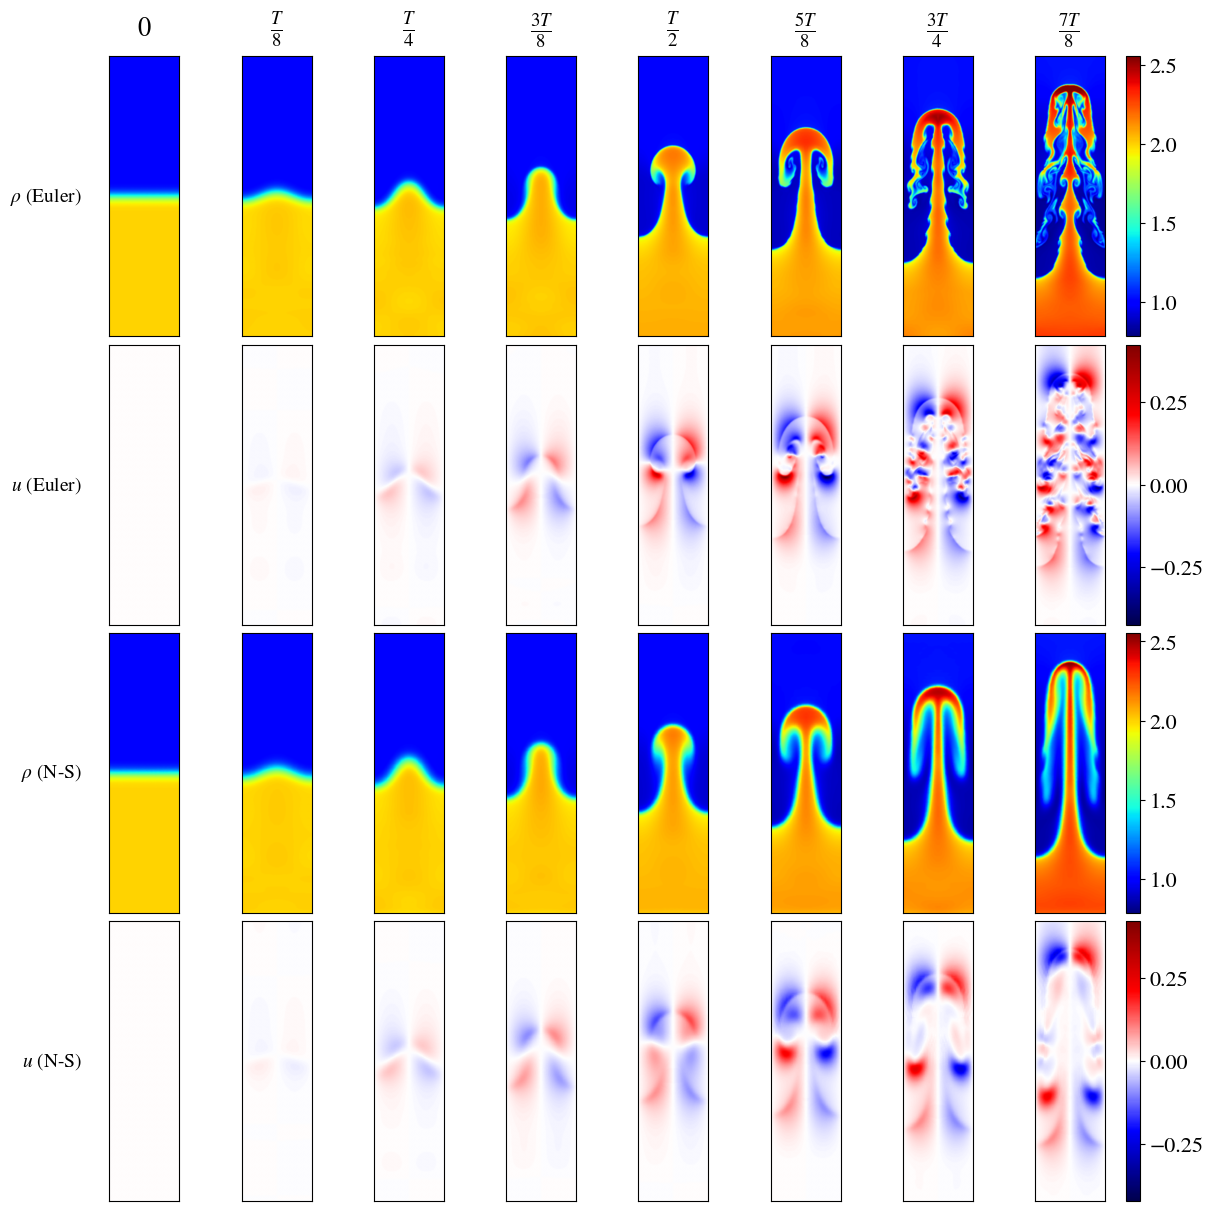

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.interpolate import griddata
import glob
import os

# ==============================================================================
# 1. VISUAL CONFIGURATION (STIX Fonts)
# ==============================================================================
mpl.rcParams['mathtext.fontset'] = 'stix'
mpl.rcParams['font.family'] = 'STIXGeneral'
mpl.rcParams['font.size'] = 16
mpl.rcParams['figure.dpi'] = 100

# ==============================================================================
# 2. CONFIGURATION
# ==============================================================================
INPUT_DIR_1 = "/users/jdtoscan/data/jdtoscan/LLM/Crunch_LLM/Results/NM_codes/CompressibleEuler_Periodic_Reflective_SmoothedInterface_ICs/2025_12_06_2123/data_npz/"
INPUT_DIR_2 = "/users/jdtoscan/data/jdtoscan/LLM/Crunch_LLM/Results/NM_codes/CompressibleNavierStokes_Periodic_NoSlipAdiabatic_SmoothedInterface/2025_12_08_0914/data_npz/"
OUTPUT_FILE = "RT_comparison.png"

# Grid Resolution (Matches 1:4 Domain Aspect Ratio)
NX, NY = 300, 1200
DOMAIN = [0.0, 0.25, 0.0, 1.0] # [x_min, x_max, y_min, y_max]

# ==============================================================================
# 3. HELPER: REGRIDDING
# ==============================================================================
def regrid_data(x, y, z, nx, ny, domain):
    """
    Converts scattered AMR data to a uniform grid using fast histogram binning.
    Fills empty pixels (holes) using nearest-neighbor interpolation.
    """
    x_edges = np.linspace(domain[0], domain[1], nx + 1)
    y_edges = np.linspace(domain[2], domain[3], ny + 1)

    # Fast Binning
    weighted_hist, _, _ = np.histogram2d(y, x, bins=[y_edges, x_edges], weights=z)
    count_hist, _, _ = np.histogram2d(y, x, bins=[y_edges, x_edges])

    # Average
    with np.errstate(divide='ignore', invalid='ignore'):
        grid = weighted_hist / count_hist

    # Fill Holes
    if np.any(np.isnan(grid)):
        yy, xx = np.mgrid[0:ny, 0:nx]
        valid_mask = ~np.isnan(grid)
        
        points = np.column_stack((yy[valid_mask], xx[valid_mask]))
        values = grid[valid_mask]
        target_points = np.column_stack((yy[~valid_mask], xx[~valid_mask]))
        
        if len(target_points) > 0 and len(values) > 0:
            filled_values = griddata(points, values, target_points, method='nearest')
            grid[~valid_mask] = filled_values

    return grid

# ==============================================================================
# 4. HELPER: LOAD DATASET AND GET GLOBAL LIMITS
# ==============================================================================
def load_dataset(input_dir, num_snapshots=8):
    """
    Load files and compute global limits for a dataset.
    Returns: files, times, global_lims
    """
    search_path = os.path.join(input_dir, "*.npz")
    files = sorted(glob.glob(search_path))
    
    if not files:
        print(f"ERROR: No .npz files found in {input_dir}")
        return None, None, None
    
    print(f"Dataset {input_dir}: Found {len(files)} snapshots.")
    
    # Get times
    times_all = []
    for f in files:
        with np.load(f) as data:
            times_all.append(float(data['t']))
    times_all = np.array(times_all)
    
    # Compute global limits
    print(f"  Computing global limits...")
    global_lims = {
        'rho': [np.inf, -np.inf],
        'u':   [np.inf, -np.inf],
    }
    
    for f in files[::5]:
        data = np.load(f)
        for var in ['rho', 'u']:
            vals = data[var].flatten()
            v_min, v_max = np.min(vals), np.max(vals)
            global_lims[var][0] = min(global_lims[var][0], v_min)
            global_lims[var][1] = max(global_lims[var][1], v_max)
    
    print(f"  Global Limits: {global_lims}")
    
    # Select equidistant snapshots
    t_end = np.max(times_all)
    targets = np.linspace(0.0, t_end, num_snapshots)
    indices = [np.argmin(np.abs(times_all - t)) for t in targets]
    
    selected_files = [files[i] for i in indices]
    selected_times = [times_all[i] for i in indices]
    
    return selected_files, selected_times, global_lims

# ==============================================================================
# 5. MAIN EXECUTION
# ==============================================================================
def main():
    num_snapshots = 8
    
    # Load both datasets
    print("=" * 80)
    print("LOADING DATASET 1 (Euler)")
    print("=" * 80)
    files_1, times_1, lims_1 = load_dataset(INPUT_DIR_1, num_snapshots)
    
    print("\n" + "=" * 80)
    print("LOADING DATASET 2 (Navier-Stokes)")
    print("=" * 80)
    files_2, times_2, lims_2 = load_dataset(INPUT_DIR_2, num_snapshots)
    
    if files_1 is None or files_2 is None:
        return
    
    # Compute combined global limits (for consistent colorbar across both datasets)
    combined_lims = {
        'rho': [min(lims_1['rho'][0], lims_2['rho'][0]), 
                max(lims_1['rho'][1], lims_2['rho'][1])],
        'u':   [min(lims_1['u'][0], lims_2['u'][0]), 
                max(lims_1['u'][1], lims_2['u'][1])],
    }
    
    print(f"\nCombined Global Limits: {combined_lims}")
    
    # --------------------------------------------------------------------------
    # GENERATE 4x8 PLOT
    # --------------------------------------------------------------------------
    print("\n" + "=" * 80)
    print("GENERATING COMPARISON PLOT")
    print("=" * 80)
    
    # Layout: 4 Rows, 8 Columns
    # Row 0: rho (Dataset 1 - Euler)
    # Row 1: u   (Dataset 1 - Euler)
    # Row 2: rho (Dataset 2 - Navier-Stokes)
    # Row 3: u   (Dataset 2 - Navier-Stokes)
    
    fig, axes = plt.subplots(4, num_snapshots, figsize=(12, 12), constrained_layout=True)
    
    row_configs = [
        {'dataset_idx': 0, 'var': 'rho', 'label': r"$\rho$ (Euler)", 'cmap': 'jet'},
        {'dataset_idx': 0, 'var': 'u',   'label': r"$u$ (Euler)",    'cmap': 'seismic'},
        {'dataset_idx': 1, 'var': 'rho', 'label': r"$\rho$ (N-S)",   'cmap': 'jet'},
        {'dataset_idx': 1, 'var': 'u',   'label': r"$u$ (N-S)",      'cmap': 'seismic'},
    ]
    
    datasets = [
        {'files': files_1, 'times': times_1},
        {'files': files_2, 'times': times_2}
    ]
    
    # Create normalized time labels (0, T/8, T/4, ...)
    time_fractions = [f"$0$", r"$\frac{T}{8}$", r"$\frac{T}{4}$", r"$\frac{3T}{8}$", 
                      r"$\frac{T}{2}$", r"$\frac{5T}{8}$", r"$\frac{3T}{4}$", r"$\frac{7T}{8}$"]
    
    # Loop over Rows
    for row_idx, config in enumerate(row_configs):
        dataset = datasets[config['dataset_idx']]
        var = config['var']
        
        # Get colorbar limits
        vmin, vmax = combined_lims[var]
        if var == 'u':
            limit = max(abs(vmin), abs(vmax))
            vmin, vmax = -limit, limit
        
        row_im = None
        
        # Loop over Columns (Time Steps)
        for col_idx in range(num_snapshots):
            ax = axes[row_idx, col_idx]
            
            # Load Data
            f_path = dataset['files'][col_idx]
            data = np.load(f_path)
            
            x = data['x'].flatten()
            y = data['y'].flatten()
            z_flat = data[var].flatten()
            
            # Regrid
            grid = regrid_data(x, y, z_flat, NX, NY, DOMAIN)
            
            # Plot
            row_im = ax.imshow(grid, origin='lower', extent=DOMAIN, 
                           cmap=config['cmap'], interpolation='bilinear', aspect='equal',
                           vmin=vmin, vmax=vmax)
            
            # --- LAYOUT LOGIC ---
            
            # 1. Time Header: ONLY on Top Row (with normalized fractions)
            if row_idx == 0:
                ax.set_title(time_fractions[col_idx], pad=15)
            
            # 2. Variable Label: ONLY on Left Column
            if col_idx == 0:
                ax.set_ylabel(config['label'], rotation=0, size=14, labelpad=20, va='center', ha='right')
            
            # Remove Axis Ticks
            ax.set_xticks([])
            ax.set_yticks([])
        
        # --- Add ONE Shared Colorbar per ROW ---
        cbar = fig.colorbar(row_im, ax=axes[row_idx, :], orientation='vertical', 
                           fraction=0.02, pad=0.02)
        cbar.locator = mpl.ticker.MaxNLocator(nbins=4)
        cbar.update_ticks()
    
    print(f"\nSaving to {OUTPUT_FILE}...")
    plt.savefig(OUTPUT_FILE, dpi=300, bbox_inches='tight')
    print("Done.")

if __name__ == "__main__":
    main()

LOADING DATASET 1 (Euler)
Dataset /users/jdtoscan/data/jdtoscan/LLM/Crunch_LLM/Results/NM_codes/CompressibleEuler_Periodic_Reflective_SmoothedInterface_ICs/2025_12_06_2123/data_npz/: Found 30 snapshots.
  Computing global limits...
  Global Limits: {'rho': [np.float64(0.7857737735068588), np.float64(2.508463393259111)]}

LOADING DATASET 2 (Navier-Stokes)
Dataset /users/jdtoscan/data/jdtoscan/LLM/Crunch_LLM/Results/NM_codes/CompressibleNavierStokes_Periodic_NoSlipAdiabatic_SmoothedInterface/2025_12_08_0914/data_npz/: Found 307 snapshots.
  Computing global limits...
  Global Limits: {'rho': [np.float64(0.8209012714245243), np.float64(2.5543082521059834)]}

Combined Global Limits: {'rho': [np.float64(0.7857737735068588), np.float64(2.5543082521059834)]}

GENERATING COMPARISON PLOT

Saving to RT_comparison.png...
Done.


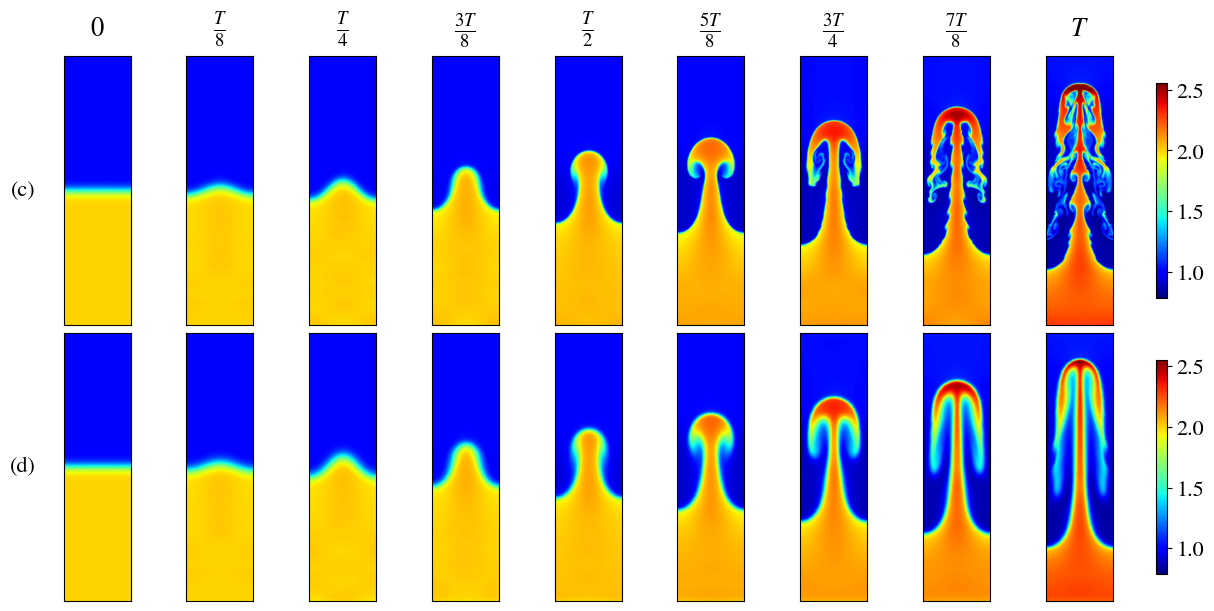

In [28]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.interpolate import griddata
import glob
import os

# ==============================================================================
# 1. VISUAL CONFIGURATION (STIX Fonts)
# ==============================================================================
mpl.rcParams['mathtext.fontset'] = 'stix'
mpl.rcParams['font.family'] = 'STIXGeneral'
mpl.rcParams['font.size'] = 16
mpl.rcParams['figure.dpi'] = 100

# ==============================================================================
# 2. CONFIGURATION
# ==============================================================================
INPUT_DIR_1 = "/users/jdtoscan/data/jdtoscan/LLM/Crunch_LLM/Results/NM_codes/CompressibleEuler_Periodic_Reflective_SmoothedInterface_ICs/2025_12_06_2123/data_npz/"
INPUT_DIR_2 = "/users/jdtoscan/data/jdtoscan/LLM/Crunch_LLM/Results/NM_codes/CompressibleNavierStokes_Periodic_NoSlipAdiabatic_SmoothedInterface/2025_12_08_0914/data_npz/"
OUTPUT_FILE = "RT_comparison.png"

# Grid Resolution (Matches 1:4 Domain Aspect Ratio)
NX, NY = 300, 1200
DOMAIN = [0.0, 0.25, 0.0, 1.0] # [x_min, x_max, y_min, y_max]

# ==============================================================================
# 3. HELPER: REGRIDDING
# ==============================================================================
def regrid_data(x, y, z, nx, ny, domain):
    """
    Converts scattered AMR data to a uniform grid using fast histogram binning.
    Fills empty pixels (holes) using nearest-neighbor interpolation.
    """
    x_edges = np.linspace(domain[0], domain[1], nx + 1)
    y_edges = np.linspace(domain[2], domain[3], ny + 1)

    # Fast Binning
    weighted_hist, _, _ = np.histogram2d(y, x, bins=[y_edges, x_edges], weights=z)
    count_hist, _, _ = np.histogram2d(y, x, bins=[y_edges, x_edges])

    # Average
    with np.errstate(divide='ignore', invalid='ignore'):
        grid = weighted_hist / count_hist

    # Fill Holes
    if np.any(np.isnan(grid)):
        yy, xx = np.mgrid[0:ny, 0:nx]
        valid_mask = ~np.isnan(grid)
        
        points = np.column_stack((yy[valid_mask], xx[valid_mask]))
        values = grid[valid_mask]
        target_points = np.column_stack((yy[~valid_mask], xx[~valid_mask]))
        
        if len(target_points) > 0 and len(values) > 0:
            filled_values = griddata(points, values, target_points, method='nearest')
            grid[~valid_mask] = filled_values

    return grid

# ==============================================================================
# 4. HELPER: LOAD DATASET AND GET GLOBAL LIMITS
# ==============================================================================
def load_dataset(input_dir, num_snapshots=9):
    """
    Load files and compute global limits for a dataset.
    Returns: files, times, global_lims
    """
    search_path = os.path.join(input_dir, "*.npz")
    files = sorted(glob.glob(search_path))
    
    if not files:
        print(f"ERROR: No .npz files found in {input_dir}")
        return None, None, None
    
    print(f"Dataset {input_dir}: Found {len(files)} snapshots.")
    
    # Get times
    times_all = []
    for f in files:
        with np.load(f) as data:
            times_all.append(float(data['t']))
    times_all = np.array(times_all)
    
    # Compute global limits for density only
    print(f"  Computing global limits...")
    global_lims = {'rho': [np.inf, -np.inf]}
    
    for f in files[::5]:
        data = np.load(f)
        vals = data['rho'].flatten()
        v_min, v_max = np.min(vals), np.max(vals)
        global_lims['rho'][0] = min(global_lims['rho'][0], v_min)
        global_lims['rho'][1] = max(global_lims['rho'][1], v_max)
    
    print(f"  Global Limits: {global_lims}")
    
    # Select equidistant snapshots from 0 to T_end
    t_end = np.max(times_all)
    targets = np.linspace(0.0, t_end, num_snapshots)
    indices = [np.argmin(np.abs(times_all - t)) for t in targets]
    
    selected_files = [files[i] for i in indices]
    selected_times = [times_all[i] for i in indices]
    
    return selected_files, selected_times, global_lims

# ==============================================================================
# 5. MAIN EXECUTION
# ==============================================================================
def main():
    num_snapshots = 9  # 0, T/8, T/4, ..., T
    
    # Load both datasets
    print("=" * 80)
    print("LOADING DATASET 1 (Euler)")
    print("=" * 80)
    files_1, times_1, lims_1 = load_dataset(INPUT_DIR_1, num_snapshots)
    
    print("\n" + "=" * 80)
    print("LOADING DATASET 2 (Navier-Stokes)")
    print("=" * 80)
    files_2, times_2, lims_2 = load_dataset(INPUT_DIR_2, num_snapshots)
    
    if files_1 is None or files_2 is None:
        return
    
    # Compute combined global limits (for consistent colorbar across both datasets)
    combined_lims = {
        'rho': [min(lims_1['rho'][0], lims_2['rho'][0]), 
                max(lims_1['rho'][1], lims_2['rho'][1])]
    }
    
    print(f"\nCombined Global Limits: {combined_lims}")
    
    # --------------------------------------------------------------------------
    # GENERATE 2x9 PLOT
    # --------------------------------------------------------------------------
    print("\n" + "=" * 80)
    print("GENERATING COMPARISON PLOT")
    print("=" * 80)
    
    # Layout: 2 Rows, 9 Columns
    # Row 0: rho (Dataset 1 - Euler)
    # Row 1: rho (Dataset 2 - Navier-Stokes)
    
    fig, axes = plt.subplots(2, num_snapshots, figsize=(12, 6), constrained_layout=True)
    
    row_configs = [
        {'dataset_idx': 0, 'label': r"(c)"},
        {'dataset_idx': 1, 'label': r"(d)"},
    ]
    
    datasets = [
        {'files': files_1, 'times': times_1},
        {'files': files_2, 'times': times_2}
    ]
    
    # Create normalized time labels (0, T/8, T/4, ..., T)
    time_fractions = [f"$0$", r"$\frac{T}{8}$", r"$\frac{T}{4}$", r"$\frac{3T}{8}$", 
                      r"$\frac{T}{2}$", r"$\frac{5T}{8}$", r"$\frac{3T}{4}$", r"$\frac{7T}{8}$", r"$T$"]
    
    vmin, vmax = combined_lims['rho']
    
    # Loop over Rows
    for row_idx, config in enumerate(row_configs):
        dataset = datasets[config['dataset_idx']]
        
        row_im = None
        
        # Loop over Columns (Time Steps)
        for col_idx in range(num_snapshots):
            ax = axes[row_idx, col_idx]
            
            # Load Data
            f_path = dataset['files'][col_idx]
            data = np.load(f_path)
            
            x = data['x'].flatten()
            y = data['y'].flatten()
            z_flat = data['rho'].flatten()
            
            # Regrid
            grid = regrid_data(x, y, z_flat, NX, NY, DOMAIN)
            
            # Plot
            row_im = ax.imshow(grid, origin='lower', extent=DOMAIN, 
                           cmap='jet', interpolation='bilinear', aspect='equal',
                           vmin=vmin, vmax=vmax)
            
            # --- LAYOUT LOGIC ---
            
            # 1. Time Header: ONLY on Top Row (with normalized fractions)
            if row_idx == 0:
                ax.set_title(time_fractions[col_idx], pad=15)
            
            # 2. Variable Label: ONLY on Left Column
            if col_idx == 0:
                ax.set_ylabel(config['label'], rotation=0, size=16, labelpad=20, va='center', ha='right')
            
            # Remove Axis Ticks
            ax.set_xticks([])
            ax.set_yticks([])
        
        # --- Add ONE Shared Colorbar per ROW ---
        cbar = fig.colorbar(row_im, ax=axes[row_idx, :], orientation='vertical', 
                           fraction=0.015, pad=0.04, shrink=0.8)
        cbar.locator = mpl.ticker.MaxNLocator(nbins=4)
        cbar.update_ticks()
    
    print(f"\nSaving to {OUTPUT_FILE}...")
    plt.savefig(OUTPUT_FILE, dpi=300, bbox_inches='tight')
    print("Done.")

if __name__ == "__main__":
    main()

Loading Cahn-Hilliard data...
CH time range: [0, 1.00]
CH target times: [0.  0.1 0.5 1. ]
CH actual times: [np.float64(0.0), np.float64(0.1), np.float64(0.5), np.float64(1.0)]
CH global limits: [-1.012, 1.013]

Loading Kelvin-Helmholtz data...
Found 99 KH snapshots.
KH time range: [0, 2.50]
KH target times: [0.    1.25  1.875 2.5  ]
KH actual times: [np.float64(0.0), np.float64(1.2589991417550168), np.float64(1.8726327056759369), np.float64(2.5)]
KH global limits (rho): [0.953, 2.140]

--- Generating Plot ---

Saving to CH_KH_comparison.png...
Done.


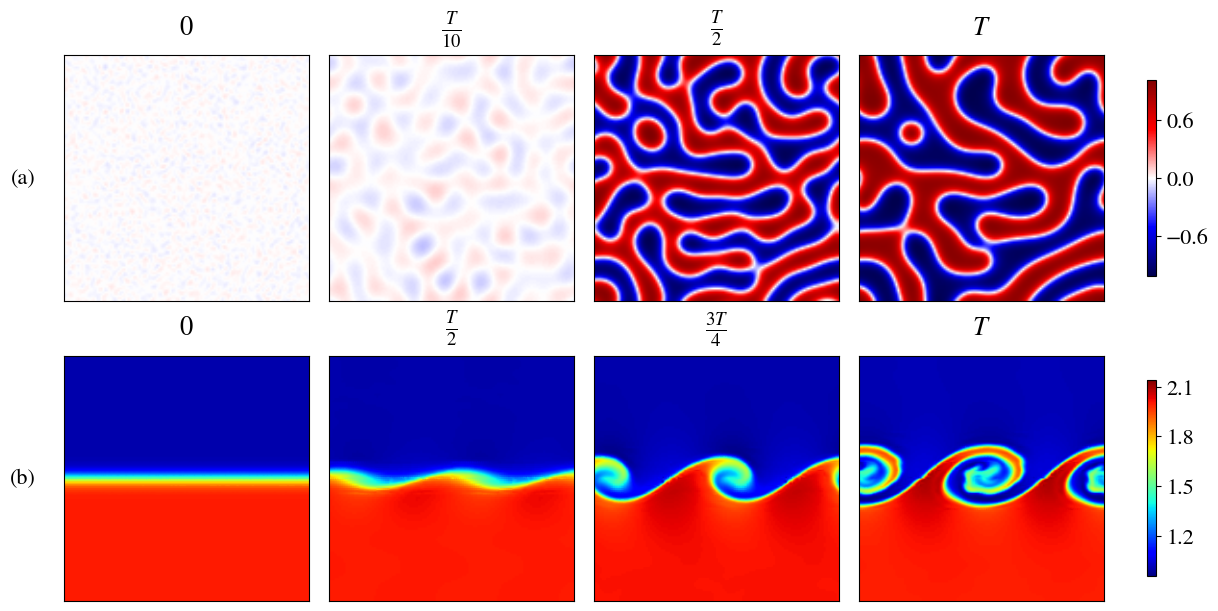

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.interpolate import griddata
import glob
import os

# ==============================================================================
# 1. VISUAL CONFIGURATION (STIX Fonts)
# ==============================================================================
mpl.rcParams['mathtext.fontset'] = 'stix'
mpl.rcParams['font.family'] = 'STIXGeneral'
mpl.rcParams['font.size'] = 16
mpl.rcParams['figure.dpi'] = 100

# ==============================================================================
# 2. CONFIGURATION
# ==============================================================================
CH_NPZ_PATH = "/users/jdtoscan/data/jdtoscan/LLM/Crunch_LLM/Results/NM_codes/CahnHilliard_Periodic_Noise/2026_01_17_1918/cahn_hilliard_spectral.npz"
KH_DIR = "/users/jdtoscan/data/jdtoscan/LLM/Crunch_LLM/Results/NM_codes/Euler_Periodic_SlipWalls_ShearLayer_ICs/2025_12_06_2249/data_npz"
OUTPUT_FILE = "CH_KH_comparison.png"

# Grid Resolution for KH
NX, NY = 1200, 1200
DOMAIN = [0.0, 1.0, 0.0, 1.0]

# ==============================================================================
# 3. HELPER: REGRIDDING
# ==============================================================================
def regrid_data(x, y, z, nx, ny, domain):
    """
    Converts scattered AMR data to a uniform grid using fast histogram binning.
    """
    x_edges = np.linspace(domain[0], domain[1], nx + 1)
    y_edges = np.linspace(domain[2], domain[3], ny + 1)

    # Fast Binning
    weighted_hist, _, _ = np.histogram2d(y, x, bins=[y_edges, x_edges], weights=z)
    count_hist, _, _ = np.histogram2d(y, x, bins=[y_edges, x_edges])

    # Average
    with np.errstate(divide='ignore', invalid='ignore'):
        grid = weighted_hist / count_hist

    # Fill Holes
    if np.any(np.isnan(grid)):
        yy, xx = np.mgrid[0:ny, 0:nx]
        valid_mask = ~np.isnan(grid)
        
        points = np.column_stack((yy[valid_mask], xx[valid_mask]))
        values = grid[valid_mask]
        
        target_mask = ~valid_mask
        target_points = np.column_stack((yy[target_mask], xx[target_mask]))
        
        if len(target_points) > 0 and len(values) > 0:
            filled_values = griddata(points, values, target_points, method='nearest')
            grid[target_mask] = filled_values

    return grid

# ==============================================================================
# 4. MAIN EXECUTION
# ==============================================================================
def main():
    # -------------------------------------------------------------------------
    # Load Cahn-Hilliard data
    # -------------------------------------------------------------------------
    print("Loading Cahn-Hilliard data...")
    ch_data = np.load(CH_NPZ_PATH)
    
    ch_t_all = ch_data['t']
    ch_x = ch_data['x']
    ch_y = ch_data['y']
    ch_usol = ch_data['usol']  # Shape: (nt, nx, ny)
    
    ch_t_end = ch_t_all[-1]
    print(f"CH time range: [0, {ch_t_end:.2f}]")
    
    # Target times: 0, T/10, T/2, T
    ch_target_times = np.array([0.0, ch_t_end/10, ch_t_end/2, ch_t_end])
    ch_indices = [np.argmin(np.abs(ch_t_all - t)) for t in ch_target_times]
    ch_actual_times = [ch_t_all[i] for i in ch_indices]
    
    print(f"CH target times: {ch_target_times}")
    print(f"CH actual times: {ch_actual_times}")
    
    # Compute CH global limits
    ch_vmin, ch_vmax = np.inf, -np.inf
    for idx in ch_indices:
        u_snapshot = ch_usol[idx, :, :]
        ch_vmin = min(ch_vmin, np.min(u_snapshot))
        ch_vmax = max(ch_vmax, np.max(u_snapshot))
    
    print(f"CH global limits: [{ch_vmin:.3f}, {ch_vmax:.3f}]")
    
    # -------------------------------------------------------------------------
    # Load Kelvin-Helmholtz data
    # -------------------------------------------------------------------------
    print("\nLoading Kelvin-Helmholtz data...")
    search_path = os.path.join(KH_DIR, "*.npz")
    kh_files = sorted(glob.glob(search_path))
    
    if not kh_files:
        print(f"ERROR: No files found in {KH_DIR}")
        return
    
    print(f"Found {len(kh_files)} KH snapshots.")
    
    # Get KH times
    kh_times_all = []
    for f in kh_files:
        with np.load(f) as data:
            kh_times_all.append(float(data['t']))
    kh_times_all = np.array(kh_times_all)
    
    kh_t_end = kh_times_all[-1]
    print(f"KH time range: [0, {kh_t_end:.2f}]")
    
    # Target times: 0, T/2, 3T/4, T (using KH's T)
    kh_target_times = np.array([0.0, kh_t_end/2, 3*kh_t_end/4, kh_t_end])
    kh_indices = [np.argmin(np.abs(kh_times_all - t)) for t in kh_target_times]
    kh_actual_times = [kh_times_all[i] for i in kh_indices]
    
    print(f"KH target times: {kh_target_times}")
    print(f"KH actual times: {kh_actual_times}")
    
    # Compute KH global limits for rho
    kh_vmin, kh_vmax = np.inf, -np.inf
    for idx in kh_indices:
        data = np.load(kh_files[idx])
        vals = data['rho'].flatten()
        kh_vmin = min(kh_vmin, np.min(vals))
        kh_vmax = max(kh_vmax, np.max(vals))
    
    print(f"KH global limits (rho): [{kh_vmin:.3f}, {kh_vmax:.3f}]")
    
    # -------------------------------------------------------------------------
    # Create 2x4 plot
    # -------------------------------------------------------------------------
    print("\n--- Generating Plot ---")
    fig, axes = plt.subplots(2, 4, figsize=(12, 6), constrained_layout=True)
    
    # Time fraction labels - different for each row
    ch_time_fractions = [r'$0$', r'$\frac{T}{10}$', r'$\frac{T}{2}$', r'$T$']
    kh_time_fractions = [r'$0$', r'$\frac{T}{2}$', r'$\frac{3T}{4}$', r'$T$']
    
    # -------------------------------------------------------------------------
    # Row 0: Cahn-Hilliard
    # -------------------------------------------------------------------------
    row_im_ch = None
    for col_idx, time_idx in enumerate(ch_indices):
        ax = axes[0, col_idx]
        t_val = ch_t_all[time_idx]
        
        # Get data
        u_snapshot = ch_usol[time_idx, :, :]
        
        # Plot
        row_im_ch = ax.imshow(u_snapshot.T, origin='lower', 
                             extent=[ch_x[0], ch_x[-1], ch_y[0], ch_y[-1]],
                             cmap='seismic', interpolation='bilinear', aspect='equal',
                             vmin=ch_vmin, vmax=ch_vmax)
        
        # Title only on top row
        ax.set_title(ch_time_fractions[col_idx], pad=15)
        
        # Y-label only on left column
        if col_idx == 0:
            ax.set_ylabel(r"(a)", rotation=0, size=16, labelpad=20, 
                         va='center', ha='right')
        
        # Remove axis ticks
        ax.set_xticks([])
        ax.set_yticks([])
    
    # Shared colorbar for CH row
    cbar_ch = fig.colorbar(row_im_ch, ax=axes[0, :], orientation='vertical', 
                        fraction=0.015, pad=0.04, shrink=0.8)
    cbar_ch.locator = mpl.ticker.MaxNLocator(nbins=4)
    cbar_ch.update_ticks()
    
    # -------------------------------------------------------------------------
    # Row 1: Kelvin-Helmholtz
    # -------------------------------------------------------------------------
    row_im_kh = None
    for col_idx, file_idx in enumerate(kh_indices):
        ax = axes[1, col_idx]
        
        # Load data
        data = np.load(kh_files[file_idx])
        t_val = data['t']
        
        x = data['x'].flatten()
        y = data['y'].flatten()
        z_flat = data['rho'].flatten()
        
        # Regrid
        grid = regrid_data(x, y, z_flat, NX, NY, DOMAIN)
        
        # Plot
        row_im_kh = ax.imshow(grid, origin='lower', extent=DOMAIN, 
                             cmap='jet', interpolation='bilinear', aspect='equal',
                             vmin=kh_vmin, vmax=kh_vmax)
        
        # Title with KH-specific time fractions
        ax.set_title(kh_time_fractions[col_idx], pad=15)
        
        # Y-label only on left column
        if col_idx == 0:
            ax.set_ylabel(r"(b)", rotation=0, size=16, labelpad=20, 
                         va='center', ha='right')
        
        # Remove axis ticks
        ax.set_xticks([])
        ax.set_yticks([])
    
    # Shared colorbar for KH row
    cbar_kh = fig.colorbar(row_im_kh, ax=axes[1, :], orientation='vertical', 
                      fraction=0.015, pad=0.04, shrink=0.8)
    cbar_kh.locator = mpl.ticker.MaxNLocator(nbins=4)
    cbar_kh.update_ticks()
    
    print(f"\nSaving to {OUTPUT_FILE}...")
    plt.savefig(OUTPUT_FILE, dpi=300, bbox_inches='tight')
    print("Done.")

if __name__ == "__main__":
    main()

LOADING DATASET 1 (Euler)
Dataset /users/jdtoscan/data/jdtoscan/LLM/Crunch_LLM/Results/NM_codes/CompressibleEuler_Periodic_Reflective_SmoothedInterface_ICs/2025_12_06_2123/data_npz/: Found 30 snapshots.
  Computing global limits...
  Global Limits: {'p': [np.float64(0.9883466346837588), np.float64(2.599590610742287)], 'u': [np.float64(-0.4229536882830515), np.float64(0.4229536883008724)]}

LOADING DATASET 2 (Navier-Stokes)
Dataset /users/jdtoscan/data/jdtoscan/LLM/Crunch_LLM/Results/NM_codes/CompressibleNavierStokes_Periodic_NoSlipAdiabatic_SmoothedInterface/2025_12_08_0914/data_npz/: Found 307 snapshots.
  Computing global limits...
  Global Limits: {'p': [np.float64(0.9853896296149003), np.float64(2.646383379719427)], 'u': [np.float64(-0.26636441528891835), np.float64(0.2663644152917831)]}

Combined Global Limits: {'p': [np.float64(0.9853896296149003), np.float64(2.646383379719427)], 'u': [np.float64(-0.4229536882830515), np.float64(0.4229536883008724)]}

GENERATING COMPARISON PLOT



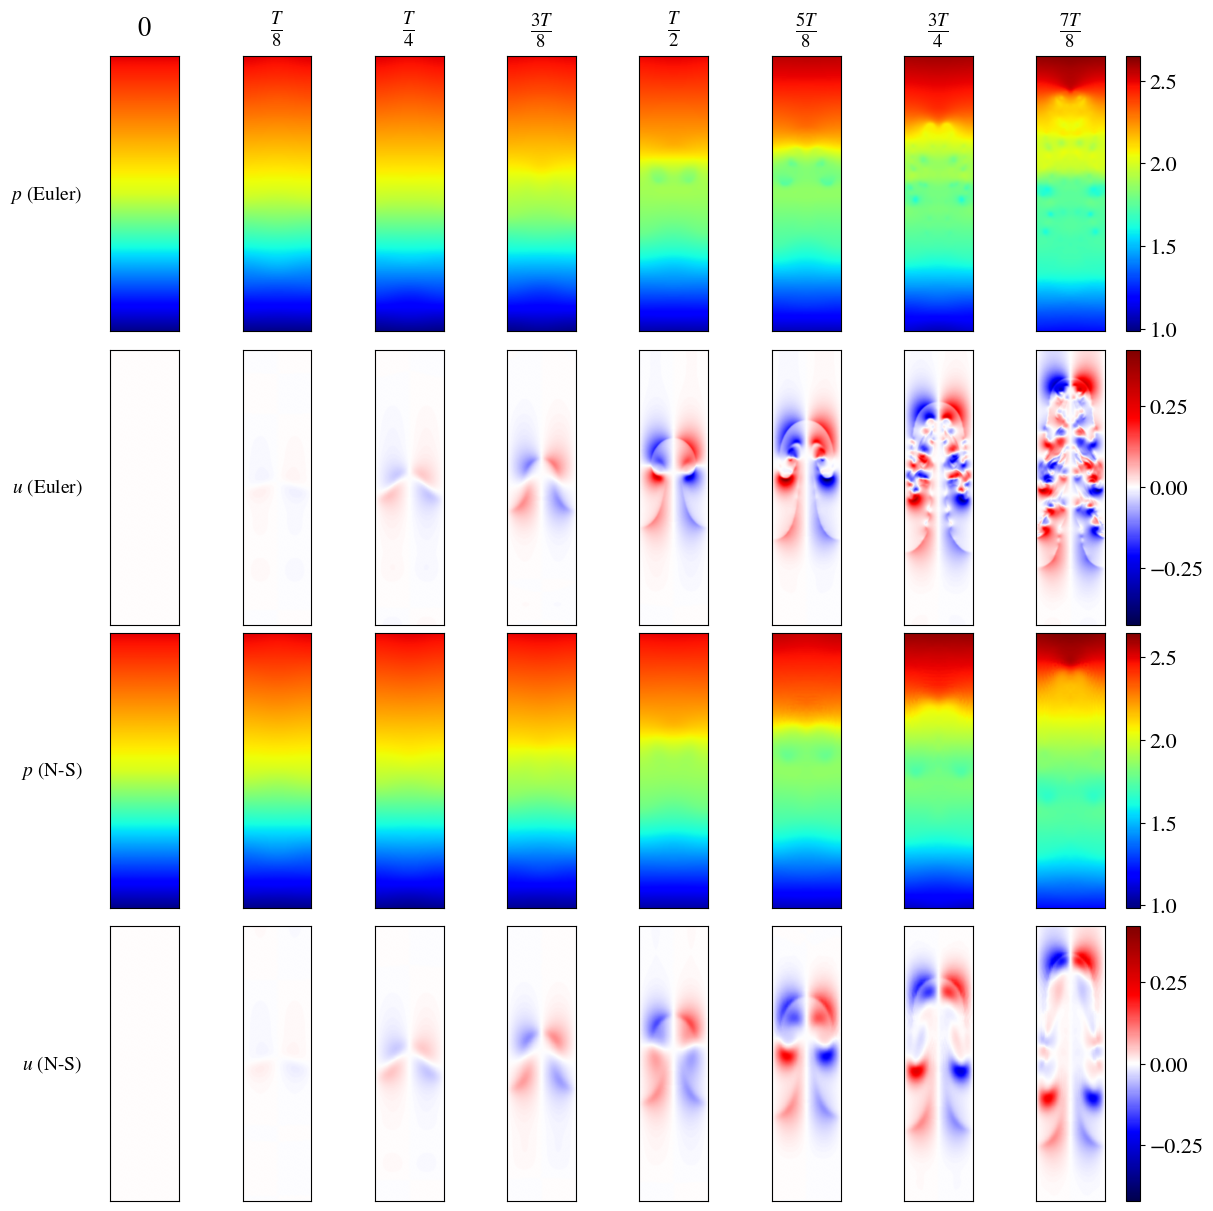

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.interpolate import griddata
import glob
import os

# ==============================================================================
# 1. VISUAL CONFIGURATION (STIX Fonts)
# ==============================================================================
mpl.rcParams['mathtext.fontset'] = 'stix'
mpl.rcParams['font.family'] = 'STIXGeneral'
mpl.rcParams['font.size'] = 16
mpl.rcParams['figure.dpi'] = 100

# ==============================================================================
# 2. CONFIGURATION
# ==============================================================================
INPUT_DIR_1 = "/users/jdtoscan/data/jdtoscan/LLM/Crunch_LLM/Results/NM_codes/CompressibleEuler_Periodic_Reflective_SmoothedInterface_ICs/2025_12_06_2123/data_npz/"
INPUT_DIR_2 = "/users/jdtoscan/data/jdtoscan/LLM/Crunch_LLM/Results/NM_codes/CompressibleNavierStokes_Periodic_NoSlipAdiabatic_SmoothedInterface/2025_12_08_0914/data_npz/"
OUTPUT_FILE = "RT_comparison_p_u.png"

# Grid Resolution (Matches 1:4 Domain Aspect Ratio)
NX, NY = 300, 1200
DOMAIN = [0.0, 0.25, 0.0, 1.0] # [x_min, x_max, y_min, y_max]

# ==============================================================================
# 3. HELPER: REGRIDDING
# ==============================================================================
def regrid_data(x, y, z, nx, ny, domain):
    """
    Converts scattered AMR data to a uniform grid using fast histogram binning.
    Fills empty pixels (holes) using nearest-neighbor interpolation.
    """
    x_edges = np.linspace(domain[0], domain[1], nx + 1)
    y_edges = np.linspace(domain[2], domain[3], ny + 1)

    # Fast Binning
    weighted_hist, _, _ = np.histogram2d(y, x, bins=[y_edges, x_edges], weights=z)
    count_hist, _, _ = np.histogram2d(y, x, bins=[y_edges, x_edges])

    # Average
    with np.errstate(divide='ignore', invalid='ignore'):
        grid = weighted_hist / count_hist

    # Fill Holes
    if np.any(np.isnan(grid)):
        yy, xx = np.mgrid[0:ny, 0:nx]
        valid_mask = ~np.isnan(grid)
        
        points = np.column_stack((yy[valid_mask], xx[valid_mask]))
        values = grid[valid_mask]
        target_points = np.column_stack((yy[~valid_mask], xx[~valid_mask]))
        
        if len(target_points) > 0 and len(values) > 0:
            filled_values = griddata(points, values, target_points, method='nearest')
            grid[~valid_mask] = filled_values

    return grid

# ==============================================================================
# 4. HELPER: LOAD DATASET AND GET GLOBAL LIMITS
# ==============================================================================
def load_dataset(input_dir, num_snapshots=8):
    """
    Load files and compute global limits for a dataset.
    Returns: files, times, global_lims
    """
    search_path = os.path.join(input_dir, "*.npz")
    files = sorted(glob.glob(search_path))
    
    if not files:
        print(f"ERROR: No .npz files found in {input_dir}")
        return None, None, None
    
    print(f"Dataset {input_dir}: Found {len(files)} snapshots.")
    
    # Get times
    times_all = []
    for f in files:
        with np.load(f) as data:
            times_all.append(float(data['t']))
    times_all = np.array(times_all)
    
    # Compute global limits
    print(f"  Computing global limits...")
    global_lims = {
        'p': [np.inf, -np.inf],
        'u':   [np.inf, -np.inf],
    }
    
    for f in files[::5]:
        data = np.load(f)
        for var in ['p', 'u']:
            vals = data[var].flatten()
            v_min, v_max = np.min(vals), np.max(vals)
            global_lims[var][0] = min(global_lims[var][0], v_min)
            global_lims[var][1] = max(global_lims[var][1], v_max)
    
    print(f"  Global Limits: {global_lims}")
    
    # Select equidistant snapshots
    t_end = np.max(times_all)
    targets = np.linspace(0.0, t_end, num_snapshots)
    indices = [np.argmin(np.abs(times_all - t)) for t in targets]
    
    selected_files = [files[i] for i in indices]
    selected_times = [times_all[i] for i in indices]
    
    return selected_files, selected_times, global_lims

# ==============================================================================
# 5. MAIN EXECUTION
# ==============================================================================
def main():
    num_snapshots = 8
    
    # Load both datasets
    print("=" * 80)
    print("LOADING DATASET 1 (Euler)")
    print("=" * 80)
    files_1, times_1, lims_1 = load_dataset(INPUT_DIR_1, num_snapshots)
    
    print("\n" + "=" * 80)
    print("LOADING DATASET 2 (Navier-Stokes)")
    print("=" * 80)
    files_2, times_2, lims_2 = load_dataset(INPUT_DIR_2, num_snapshots)
    
    if files_1 is None or files_2 is None:
        return
    
    # Compute combined global limits (for consistent colorbar across both datasets)
    combined_lims = {
        'p': [min(lims_1['p'][0], lims_2['p'][0]), 
              max(lims_1['p'][1], lims_2['p'][1])],
        'u': [min(lims_1['u'][0], lims_2['u'][0]), 
              max(lims_1['u'][1], lims_2['u'][1])],
    }
    
    print(f"\nCombined Global Limits: {combined_lims}")
    
    # --------------------------------------------------------------------------
    # GENERATE 4x8 PLOT
    # --------------------------------------------------------------------------
    print("\n" + "=" * 80)
    print("GENERATING COMPARISON PLOT")
    print("=" * 80)
    
    # Layout: 4 Rows, 8 Columns
    # Row 0: p (Dataset 1 - Euler)
    # Row 1: u (Dataset 1 - Euler)
    # Row 2: p (Dataset 2 - Navier-Stokes)
    # Row 3: u (Dataset 2 - Navier-Stokes)
    
    fig, axes = plt.subplots(4, num_snapshots, figsize=(12, 12), constrained_layout=True)
    
    row_configs = [
        {'dataset_idx': 0, 'var': 'p', 'label': r"$p$ (Euler)", 'cmap': 'jet'},
        {'dataset_idx': 0, 'var': 'u', 'label': r"$u$ (Euler)", 'cmap': 'seismic'},
        {'dataset_idx': 1, 'var': 'p', 'label': r"$p$ (N-S)",   'cmap': 'jet'},
        {'dataset_idx': 1, 'var': 'u', 'label': r"$u$ (N-S)",   'cmap': 'seismic'},
    ]
    
    datasets = [
        {'files': files_1, 'times': times_1},
        {'files': files_2, 'times': times_2}
    ]
    
    # Create normalized time labels (0, T/8, T/4, ...)
    time_fractions = [f"$0$", r"$\frac{T}{8}$", r"$\frac{T}{4}$", r"$\frac{3T}{8}$", 
                      r"$\frac{T}{2}$", r"$\frac{5T}{8}$", r"$\frac{3T}{4}$", r"$\frac{7T}{8}$"]
    
    # Loop over Rows
    for row_idx, config in enumerate(row_configs):
        dataset = datasets[config['dataset_idx']]
        var = config['var']
        
        # Get colorbar limits
        vmin, vmax = combined_lims[var]
        if var == 'u':
            limit = max(abs(vmin), abs(vmax))
            vmin, vmax = -limit, limit
        
        row_im = None
        
        # Loop over Columns (Time Steps)
        for col_idx in range(num_snapshots):
            ax = axes[row_idx, col_idx]
            
            # Load Data
            f_path = dataset['files'][col_idx]
            data = np.load(f_path)
            
            x = data['x'].flatten()
            y = data['y'].flatten()
            z_flat = data[var].flatten()
            
            # Regrid
            grid = regrid_data(x, y, z_flat, NX, NY, DOMAIN)
            
            # Plot
            row_im = ax.imshow(grid, origin='lower', extent=DOMAIN, 
                           cmap=config['cmap'], interpolation='bilinear', aspect='equal',
                           vmin=vmin, vmax=vmax)
            
            # --- LAYOUT LOGIC ---
            
            # 1. Time Header: ONLY on Top Row (with normalized fractions)
            if row_idx == 0:
                ax.set_title(time_fractions[col_idx], pad=15)
            
            # 2. Variable Label: ONLY on Left Column
            if col_idx == 0:
                ax.set_ylabel(config['label'], rotation=0, size=14, labelpad=20, va='center', ha='right')
            
            # Remove Axis Ticks
            ax.set_xticks([])
            ax.set_yticks([])
        
        # --- Add ONE Shared Colorbar per ROW ---
        cbar = fig.colorbar(row_im, ax=axes[row_idx, :], orientation='vertical', 
                           fraction=0.02, pad=0.02)
        cbar.locator = mpl.ticker.MaxNLocator(nbins=4)
        cbar.update_ticks()
    
    print(f"\nSaving to {OUTPUT_FILE}...")
    plt.savefig(OUTPUT_FILE, dpi=300, bbox_inches='tight')
    print("Done.")

if __name__ == "__main__":
    main()

Loading Kelvin-Helmholtz data...
Found 99 KH snapshots.
KH time range: [0, 2.50]
KH target times: [0.    1.25  1.875 2.5  ]
KH actual times: [np.float64(0.0), np.float64(1.2589991417550168), np.float64(1.8726327056759369), np.float64(2.5)]
KH global limits:
  u: [-0.873, 0.733]
  v: [-0.480, 0.526]
  p: [2.111, 2.669]

--- Generating Plot ---

Saving to KH_uvp_comparison.png...
Done.


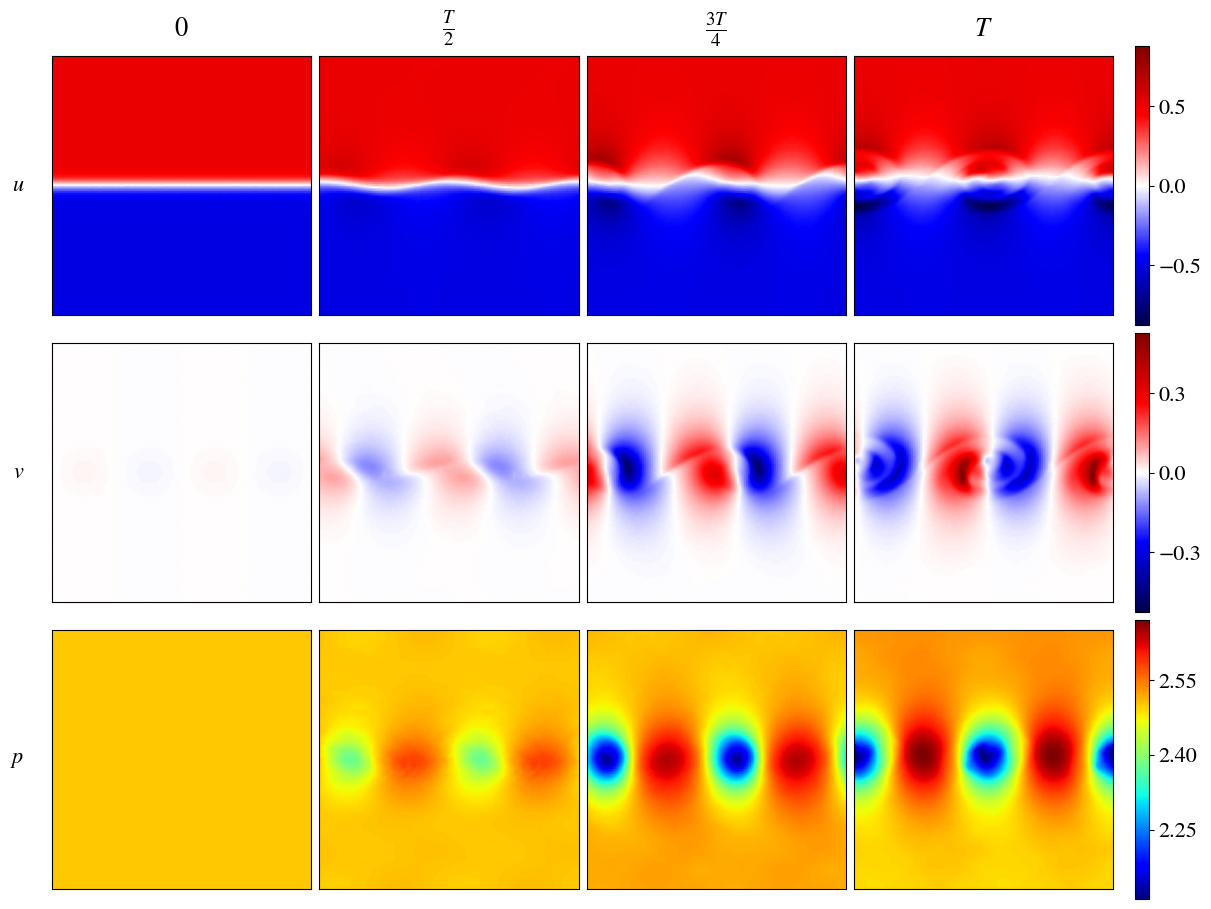

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.interpolate import griddata
import glob
import os

# ==============================================================================
# 1. VISUAL CONFIGURATION (STIX Fonts)
# ==============================================================================
mpl.rcParams['mathtext.fontset'] = 'stix'
mpl.rcParams['font.family'] = 'STIXGeneral'
mpl.rcParams['font.size'] = 16
mpl.rcParams['figure.dpi'] = 100

# ==============================================================================
# 2. CONFIGURATION
# ==============================================================================
KH_DIR = "/users/jdtoscan/data/jdtoscan/LLM/Crunch_LLM/Results/NM_codes/Euler_Periodic_SlipWalls_ShearLayer_ICs/2025_12_06_2249/data_npz"
OUTPUT_FILE = "KH_uvp_comparison.png"

# Grid Resolution for KH
NX, NY = 1200, 1200
DOMAIN = [0.0, 1.0, 0.0, 1.0]

# ==============================================================================
# 3. HELPER: REGRIDDING
# ==============================================================================
def regrid_data(x, y, z, nx, ny, domain):
    """
    Converts scattered AMR data to a uniform grid using fast histogram binning.
    """
    x_edges = np.linspace(domain[0], domain[1], nx + 1)
    y_edges = np.linspace(domain[2], domain[3], ny + 1)

    # Fast Binning
    weighted_hist, _, _ = np.histogram2d(y, x, bins=[y_edges, x_edges], weights=z)
    count_hist, _, _ = np.histogram2d(y, x, bins=[y_edges, x_edges])

    # Average
    with np.errstate(divide='ignore', invalid='ignore'):
        grid = weighted_hist / count_hist

    # Fill Holes
    if np.any(np.isnan(grid)):
        yy, xx = np.mgrid[0:ny, 0:nx]
        valid_mask = ~np.isnan(grid)
        
        points = np.column_stack((yy[valid_mask], xx[valid_mask]))
        values = grid[valid_mask]
        
        target_mask = ~valid_mask
        target_points = np.column_stack((yy[target_mask], xx[target_mask]))
        
        if len(target_points) > 0 and len(values) > 0:
            filled_values = griddata(points, values, target_points, method='nearest')
            grid[target_mask] = filled_values

    return grid

# ==============================================================================
# 4. MAIN EXECUTION
# ==============================================================================
def main():
    # -------------------------------------------------------------------------
    # Load Kelvin-Helmholtz data
    # -------------------------------------------------------------------------
    print("Loading Kelvin-Helmholtz data...")
    search_path = os.path.join(KH_DIR, "*.npz")
    kh_files = sorted(glob.glob(search_path))
    
    if not kh_files:
        print(f"ERROR: No files found in {KH_DIR}")
        return
    
    print(f"Found {len(kh_files)} KH snapshots.")
    
    # Get KH times
    kh_times_all = []
    for f in kh_files:
        with np.load(f) as data:
            kh_times_all.append(float(data['t']))
    kh_times_all = np.array(kh_times_all)
    
    kh_t_end = kh_times_all[-1]
    print(f"KH time range: [0, {kh_t_end:.2f}]")
    
    # Target times: 0, T/2, 3T/4, T (using KH's T)
    kh_target_times = np.array([0.0, kh_t_end/2, 3*kh_t_end/4, kh_t_end])
    kh_indices = [np.argmin(np.abs(kh_times_all - t)) for t in kh_target_times]
    kh_actual_times = [kh_times_all[i] for i in kh_indices]
    
    print(f"KH target times: {kh_target_times}")
    print(f"KH actual times: {kh_actual_times}")
    
    # Compute KH global limits for u, v, p
    kh_limits = {
        'u': [np.inf, -np.inf],
        'v': [np.inf, -np.inf],
        'p': [np.inf, -np.inf]
    }
    
    for idx in kh_indices:
        data = np.load(kh_files[idx])
        for var in ['u', 'v', 'p']:
            vals = data[var].flatten()
            kh_limits[var][0] = min(kh_limits[var][0], np.min(vals))
            kh_limits[var][1] = max(kh_limits[var][1], np.max(vals))
    
    print(f"KH global limits:")
    for var in ['u', 'v', 'p']:
        print(f"  {var}: [{kh_limits[var][0]:.3f}, {kh_limits[var][1]:.3f}]")
    
    # -------------------------------------------------------------------------
    # Create 3x4 plot (3 rows: u, v, p; 4 columns: time snapshots)
    # -------------------------------------------------------------------------
    print("\n--- Generating Plot ---")
    fig, axes = plt.subplots(3, 4, figsize=(12, 9), constrained_layout=True)
    
    # Time fraction labels
    time_fractions = [r'$0$', r'$\frac{T}{2}$', r'$\frac{3T}{4}$', r'$T$']
    
    # -------------------------------------------------------------------------
    # Row 0: KH u-velocity
    # -------------------------------------------------------------------------
    row_im_u = None
    u_vmin, u_vmax = kh_limits['u']
    # Make symmetric for velocity
    u_limit = max(abs(u_vmin), abs(u_vmax))
    u_vmin, u_vmax = -u_limit, u_limit
    
    for col_idx, file_idx in enumerate(kh_indices):
        ax = axes[0, col_idx]
        
        # Load data
        data = np.load(kh_files[file_idx])
        
        x = data['x'].flatten()
        y = data['y'].flatten()
        z_flat = data['u'].flatten()
        
        # Regrid
        grid = regrid_data(x, y, z_flat, NX, NY, DOMAIN)
        
        # Plot
        row_im_u = ax.imshow(grid, origin='lower', extent=DOMAIN, 
                             cmap='seismic', interpolation='bilinear', aspect='equal',
                             vmin=u_vmin, vmax=u_vmax)
        
        # Title with time fractions (only on top row)
        ax.set_title(time_fractions[col_idx], pad=15)
        
        # Y-label only on left column
        if col_idx == 0:
            ax.set_ylabel(r"$u$", rotation=0, size=16, labelpad=20, 
                         va='center', ha='right')
        
        # Remove axis ticks
        ax.set_xticks([])
        ax.set_yticks([])
    
    # Shared colorbar for u row
    cbar_u = fig.colorbar(row_im_u, ax=axes[0, :], orientation='vertical', 
                      fraction=0.02, pad=0.02)
    cbar_u.locator = mpl.ticker.MaxNLocator(nbins=4)
    cbar_u.update_ticks()
    
    # -------------------------------------------------------------------------
    # Row 1: KH v-velocity
    # -------------------------------------------------------------------------
    row_im_v = None
    v_vmin, v_vmax = kh_limits['v']
    # Make symmetric for velocity
    v_limit = max(abs(v_vmin), abs(v_vmax))
    v_vmin, v_vmax = -v_limit, v_limit
    
    for col_idx, file_idx in enumerate(kh_indices):
        ax = axes[1, col_idx]
        
        # Load data
        data = np.load(kh_files[file_idx])
        
        x = data['x'].flatten()
        y = data['y'].flatten()
        z_flat = data['v'].flatten()
        
        # Regrid
        grid = regrid_data(x, y, z_flat, NX, NY, DOMAIN)
        
        # Plot
        row_im_v = ax.imshow(grid, origin='lower', extent=DOMAIN, 
                             cmap='seismic', interpolation='bilinear', aspect='equal',
                             vmin=v_vmin, vmax=v_vmax)
        
        # Y-label only on left column
        if col_idx == 0:
            ax.set_ylabel(r"$v$", rotation=0, size=16, labelpad=20, 
                         va='center', ha='right')
        
        # Remove axis ticks
        ax.set_xticks([])
        ax.set_yticks([])
    
    # Shared colorbar for v row
    cbar_v = fig.colorbar(row_im_v, ax=axes[1, :], orientation='vertical', 
                      fraction=0.02, pad=0.02)
    cbar_v.locator = mpl.ticker.MaxNLocator(nbins=4)
    cbar_v.update_ticks()
    
    # -------------------------------------------------------------------------
    # Row 2: KH pressure
    # -------------------------------------------------------------------------
    row_im_p = None
    p_vmin, p_vmax = kh_limits['p']
    
    for col_idx, file_idx in enumerate(kh_indices):
        ax = axes[2, col_idx]
        
        # Load data
        data = np.load(kh_files[file_idx])
        
        x = data['x'].flatten()
        y = data['y'].flatten()
        z_flat = data['p'].flatten()
        
        # Regrid
        grid = regrid_data(x, y, z_flat, NX, NY, DOMAIN)
        
        # Plot
        row_im_p = ax.imshow(grid, origin='lower', extent=DOMAIN, 
                             cmap='jet', interpolation='bilinear', aspect='equal',
                             vmin=p_vmin, vmax=p_vmax)
        
        # Y-label only on left column
        if col_idx == 0:
            ax.set_ylabel(r"$p$", rotation=0, size=16, labelpad=20, 
                         va='center', ha='right')
        
        # Remove axis ticks
        ax.set_xticks([])
        ax.set_yticks([])
    
    # Shared colorbar for p row
    cbar_p = fig.colorbar(row_im_p, ax=axes[2, :], orientation='vertical', 
                      fraction=0.02, pad=0.02)
    cbar_p.locator = mpl.ticker.MaxNLocator(nbins=4)
    cbar_p.update_ticks()
    
    print(f"\nSaving to {OUTPUT_FILE}...")
    plt.savefig(OUTPUT_FILE, dpi=300, bbox_inches='tight')
    print("Done.")

if __name__ == "__main__":
    main()

Loading Kelvin-Helmholtz data...
Found 99 KH snapshots.
KH time range: [0, 2.50]
KH target times: [0.    1.25  1.875 2.5  ]
KH actual times: [np.float64(0.0), np.float64(1.2589991417550168), np.float64(1.8726327056759369), np.float64(2.5)]
KH global limits:
  u: [-0.873, 0.733]
  v: [-0.480, 0.526]
  p: [2.111, 2.669]

--- Generating Plot ---

Saving to KH_uvp_comparison.png...
Done.


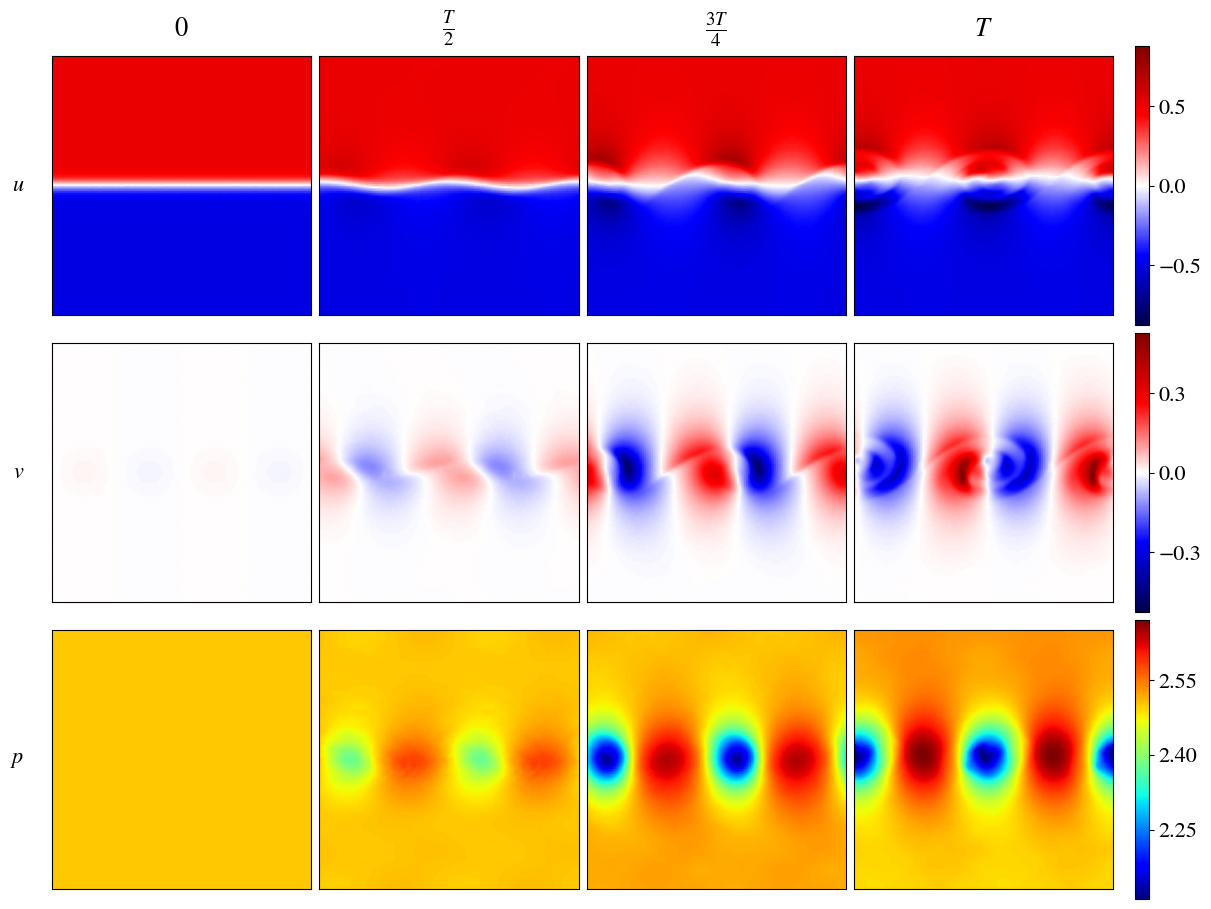

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.interpolate import griddata
import glob
import os

# ==============================================================================
# 1. VISUAL CONFIGURATION (STIX Fonts)
# ==============================================================================
mpl.rcParams['mathtext.fontset'] = 'stix'
mpl.rcParams['font.family'] = 'STIXGeneral'
mpl.rcParams['font.size'] = 16
mpl.rcParams['figure.dpi'] = 100

# ==============================================================================
# 2. CONFIGURATION
# ==============================================================================
KH_DIR = "/users/jdtoscan/data/jdtoscan/LLM/Crunch_LLM/Results/NM_codes/Euler_Periodic_SlipWalls_ShearLayer_ICs/2025_12_06_2249/data_npz"
OUTPUT_FILE = "KH_uvp_comparison.png"

# Grid Resolution for KH
NX, NY = 1200, 1200
DOMAIN = [0.0, 1.0, 0.0, 1.0]

# ==============================================================================
# 3. HELPER: REGRIDDING
# ==============================================================================
def regrid_data(x, y, z, nx, ny, domain):
    """
    Converts scattered AMR data to a uniform grid using fast histogram binning.
    """
    x_edges = np.linspace(domain[0], domain[1], nx + 1)
    y_edges = np.linspace(domain[2], domain[3], ny + 1)

    # Fast Binning
    weighted_hist, _, _ = np.histogram2d(y, x, bins=[y_edges, x_edges], weights=z)
    count_hist, _, _ = np.histogram2d(y, x, bins=[y_edges, x_edges])

    # Average
    with np.errstate(divide='ignore', invalid='ignore'):
        grid = weighted_hist / count_hist

    # Fill Holes
    if np.any(np.isnan(grid)):
        yy, xx = np.mgrid[0:ny, 0:nx]
        valid_mask = ~np.isnan(grid)
        
        points = np.column_stack((yy[valid_mask], xx[valid_mask]))
        values = grid[valid_mask]
        
        target_mask = ~valid_mask
        target_points = np.column_stack((yy[target_mask], xx[target_mask]))
        
        if len(target_points) > 0 and len(values) > 0:
            filled_values = griddata(points, values, target_points, method='nearest')
            grid[target_mask] = filled_values

    return grid

# ==============================================================================
# 4. MAIN EXECUTION
# ==============================================================================
def main():
    # -------------------------------------------------------------------------
    # Load Kelvin-Helmholtz data
    # -------------------------------------------------------------------------
    print("Loading Kelvin-Helmholtz data...")
    search_path = os.path.join(KH_DIR, "*.npz")
    kh_files = sorted(glob.glob(search_path))
    
    if not kh_files:
        print(f"ERROR: No files found in {KH_DIR}")
        return
    
    print(f"Found {len(kh_files)} KH snapshots.")
    
    # Get KH times
    kh_times_all = []
    for f in kh_files:
        with np.load(f) as data:
            kh_times_all.append(float(data['t']))
    kh_times_all = np.array(kh_times_all)
    
    kh_t_end = kh_times_all[-1]
    print(f"KH time range: [0, {kh_t_end:.2f}]")
    
    # Target times: 0, T/2, 3T/4, T (using KH's T)
    kh_target_times = np.array([0.0, kh_t_end/2, 3*kh_t_end/4, kh_t_end])
    kh_indices = [np.argmin(np.abs(kh_times_all - t)) for t in kh_target_times]
    kh_actual_times = [kh_times_all[i] for i in kh_indices]
    
    print(f"KH target times: {kh_target_times}")
    print(f"KH actual times: {kh_actual_times}")
    
    # Compute KH global limits for u, v, p
    kh_limits = {
        'u': [np.inf, -np.inf],
        'v': [np.inf, -np.inf],
        'p': [np.inf, -np.inf]
    }
    
    for idx in kh_indices:
        data = np.load(kh_files[idx])
        for var in ['u', 'v', 'p']:
            vals = data[var].flatten()
            kh_limits[var][0] = min(kh_limits[var][0], np.min(vals))
            kh_limits[var][1] = max(kh_limits[var][1], np.max(vals))
    
    print(f"KH global limits:")
    for var in ['u', 'v', 'p']:
        print(f"  {var}: [{kh_limits[var][0]:.3f}, {kh_limits[var][1]:.3f}]")
    
    # -------------------------------------------------------------------------
    # Create 3x4 plot (3 rows: u, v, p; 4 columns: time snapshots)
    # -------------------------------------------------------------------------
    print("\n--- Generating Plot ---")
    fig, axes = plt.subplots(3, 4, figsize=(12, 9), constrained_layout=True)
    
    # Time fraction labels
    time_fractions = [r'$0$', r'$\frac{T}{2}$', r'$\frac{3T}{4}$', r'$T$']
    
    # -------------------------------------------------------------------------
    # Row 0: KH u-velocity
    # -------------------------------------------------------------------------
    row_im_u = None
    u_vmin, u_vmax = kh_limits['u']
    # Make symmetric for velocity
    u_limit = max(abs(u_vmin), abs(u_vmax))
    u_vmin, u_vmax = -u_limit, u_limit
    
    for col_idx, file_idx in enumerate(kh_indices):
        ax = axes[0, col_idx]
        
        # Load data
        data = np.load(kh_files[file_idx])
        
        x = data['x'].flatten()
        y = data['y'].flatten()
        z_flat = data['u'].flatten()
        
        # Regrid
        grid = regrid_data(x, y, z_flat, NX, NY, DOMAIN)
        
        # Plot
        row_im_u = ax.imshow(grid, origin='lower', extent=DOMAIN, 
                             cmap='seismic', interpolation='bilinear', aspect='equal',
                             vmin=u_vmin, vmax=u_vmax)
        
        # Title with time fractions (only on top row)
        ax.set_title(time_fractions[col_idx], pad=15)
        
        # Y-label only on left column
        if col_idx == 0:
            ax.set_ylabel(r"$u$", rotation=0, size=16, labelpad=20, 
                         va='center', ha='right')
        
        # Remove axis ticks
        ax.set_xticks([])
        ax.set_yticks([])
    
    # Shared colorbar for u row
    cbar_u = fig.colorbar(row_im_u, ax=axes[0, :], orientation='vertical', 
                      fraction=0.02, pad=0.02)
    cbar_u.locator = mpl.ticker.MaxNLocator(nbins=4)
    cbar_u.update_ticks()
    
    # -------------------------------------------------------------------------
    # Row 1: KH v-velocity
    # -------------------------------------------------------------------------
    row_im_v = None
    v_vmin, v_vmax = kh_limits['v']
    # Make symmetric for velocity
    v_limit = max(abs(v_vmin), abs(v_vmax))
    v_vmin, v_vmax = -v_limit, v_limit
    
    for col_idx, file_idx in enumerate(kh_indices):
        ax = axes[1, col_idx]
        
        # Load data
        data = np.load(kh_files[file_idx])
        
        x = data['x'].flatten()
        y = data['y'].flatten()
        z_flat = data['v'].flatten()
        
        # Regrid
        grid = regrid_data(x, y, z_flat, NX, NY, DOMAIN)
        
        # Plot
        row_im_v = ax.imshow(grid, origin='lower', extent=DOMAIN, 
                             cmap='seismic', interpolation='bilinear', aspect='equal',
                             vmin=v_vmin, vmax=v_vmax)
        
        # Y-label only on left column
        if col_idx == 0:
            ax.set_ylabel(r"$v$", rotation=0, size=16, labelpad=20, 
                         va='center', ha='right')
        
        # Remove axis ticks
        ax.set_xticks([])
        ax.set_yticks([])
    
    # Shared colorbar for v row
    cbar_v = fig.colorbar(row_im_v, ax=axes[1, :], orientation='vertical', 
                      fraction=0.02, pad=0.02)
    cbar_v.locator = mpl.ticker.MaxNLocator(nbins=4)
    cbar_v.update_ticks()
    
    # -------------------------------------------------------------------------
    # Row 2: KH pressure
    # -------------------------------------------------------------------------
    row_im_p = None
    p_vmin, p_vmax = kh_limits['p']
    
    for col_idx, file_idx in enumerate(kh_indices):
        ax = axes[2, col_idx]
        
        # Load data
        data = np.load(kh_files[file_idx])
        
        x = data['x'].flatten()
        y = data['y'].flatten()
        z_flat = data['p'].flatten()
        
        # Regrid
        grid = regrid_data(x, y, z_flat, NX, NY, DOMAIN)
        
        # Plot
        row_im_p = ax.imshow(grid, origin='lower', extent=DOMAIN, 
                             cmap='jet', interpolation='bilinear', aspect='equal',
                             vmin=p_vmin, vmax=p_vmax)
        
        # Y-label only on left column
        if col_idx == 0:
            ax.set_ylabel(r"$p$", rotation=0, size=16, labelpad=20, 
                         va='center', ha='right')
        
        # Remove axis ticks
        ax.set_xticks([])
        ax.set_yticks([])
    
    # Shared colorbar for p row
    cbar_p = fig.colorbar(row_im_p, ax=axes[2, :], orientation='vertical', 
                      fraction=0.02, pad=0.02)
    cbar_p.locator = mpl.ticker.MaxNLocator(nbins=4)
    cbar_p.update_ticks()
    
    print(f"\nSaving to {OUTPUT_FILE}...")
    plt.savefig(OUTPUT_FILE, dpi=300, bbox_inches='tight')
    print("Done.")

if __name__ == "__main__":
    main()